# 5장 보충: 복수 출력 경사하강법을 수학으로 이해하기

## 0. 저자가 말하려는 것 (알맹이)

5장 제목은 **"경사하강법 일반화하기"** 입니다. 4장에서는 가중치가 **1개**인 신경망에서
"오차를 줄이려면 가중치를 어느 방향으로, 얼마나 움직여야 하는가"를 구했고, 답은 이 한 줄이었습니다.

$$\text{weight\_delta} = \text{input} \times \text{delta}$$

5장은 이 한 줄이 **가중치가 몇 개든, 입력·출력이 몇 개든 그대로 통한다**는 것을 세 단계로 보여 줍니다.

| 절 | 구조 | 가중치마다 다른 것 | 모든 가중치가 함께 쓰는 것 |
|---|---|---|---|
| 복수 입력 | 입력 3 → 출력 1 | input | delta (출력이 하나뿐이라) |
| **복수 출력 (이 노트)** | 입력 1 → 출력 3 | delta | input (입력이 하나뿐이라) |
| 복수 입력·복수 출력 | 입력 3 → 출력 3 | 둘 다 | — |

어느 경우든 가중치 **하나**에 대해 하는 일은 똑같습니다.

> **그 가중치가 잇는 입력값 × 그 가중치가 잇는 출력의 delta** 를 구하고, 그 반대 방향으로 조금(α배) 움직인다.

저자가 "다양한 아키텍처가 이 단순한 한 가지 원리를 학습에 일관되게 사용한다"고 한 것이 이것입니다.
신경망의 모양(아키텍처)이 바뀌면 **어떤 입력과 어떤 delta가 짝지어지는지**만 바뀌고, 학습 규칙은 바뀌지 않습니다.

복수 출력은 그중 가장 단순한 경우입니다. 이 노트는 그 이유를 밑바닥 수학부터 따라갑니다.

1. 예측과 오차를 **가중치의 함수**로 본다
2. **기울기**란 무엇이고, 왜 `input × delta`가 기울기인가 (미분 공식 없이 중학교 대수로만)
3. 왜 기울기의 **반대 방향**으로 움직이면 오차가 줄어드나
4. 출력이 3개일 때 가중치들이 왜 **서로 독립**인가 (편미분)
5. 반복하면 값이 어떻게 변하나 (손계산 표, 반복 테이블, 그래프, 그리고 한 줄짜리 닫힌 식)
6. 복수 입력·복수 출력으로 일반화, 그리고 "확률적" 경사하강법의 뜻

## 1. 기호 정하기, 그리고 "함수"로 보기

책 코드의 이름을 짧은 기호로 바꿉니다. 종이에 쓸 때도 이 기호가 편합니다.

| 책 코드 | 기호 | 뜻 | 이 절의 값 |
|---|---|---|---|
| `input` | $x$ | 입력 (경기 전 승률) | $0.65$ |
| `weights[k]` | $w_k$ | k번째 출력으로 가는 가중치 | $w_0=0.3,\ w_1=0.2,\ w_2=0.9$ |
| `pred[k]` | $p_k$ | k번째 예측 | |
| `true[k]` | $y_k$ | k번째 정답 | $y_0=0.1$ (부상), $y_1=1$ (승리), $y_2=0.1$ (슬픔) |
| `delta[k]` | $\delta_k$ | 예측 − 정답 | |
| `error[k]` | $e_k$ | 오차 | |
| `alpha` | $\alpha$ | 학습률 | $0.1$ |

$k$는 0, 1, 2 중 하나이고 각각 부상·승리·슬픔 출력입니다.

### 1-1. 예측은 곱셈 하나

$$p_k = x \cdot w_k$$

출력이 3개라도 곱셈을 세 번 할 뿐입니다.

$$p_0 = 0.65\times0.3 = 0.195,\qquad p_1 = 0.65\times0.2 = 0.13,\qquad p_2 = 0.65\times0.9 = 0.585$$

### 1-2. delta와 오차

$$\delta_k = p_k - y_k,\qquad e_k = (p_k - y_k)^2 = \delta_k^{\,2}$$

- $\delta_k$의 **부호**는 방향입니다. $+$면 예측이 너무 높고, $-$면 너무 낮습니다.
- $\delta_k$의 **크기**는 얼마나 틀렸는지입니다.
- 오차 $e_k$는 delta를 제곱한 값입니다. 제곱하는 이유는 두 가지입니다.
  1. 높게 틀리든 낮게 틀리든 오차가 항상 0 이상이고, **0일 때만 완벽**합니다.
  2. 많이 틀릴수록 더 크게 벌합니다. 0.1 틀리면 0.01, 1 틀리면 1.

### 1-3. 관점 바꾸기: 오차는 "가중치의 함수"다

학습하는 동안 $x$(입력)와 $y_k$(정답)는 데이터라서 **고정**입니다. 바꿀 수 있는 것은 $w_k$뿐입니다.
그래서 오차를 $w_k$ 하나만의 함수로 쓸 수 있습니다.

$$e_k(w_k) = (x\,w_k - y_k)^2$$

승리 출력($x=0.65,\ y_1=1$)에 대입하면 $e_1(w_1) = (0.65\,w_1 - 1)^2$ 입니다. $w_1$에 숫자를 넣어 봅니다 (종이로 따라해 보세요).

| $w_1$ | $p_1=0.65\,w_1$ | $\delta_1=p_1-1$ | $e_1=\delta_1^{\,2}$ |
|---|---|---|---|
| 0 | 0 | −1 | 1 |
| **0.2 (지금)** | 0.13 | −0.87 | 0.7569 |
| 0.5 | 0.325 | −0.675 | 0.455625 |
| 1.0 | 0.65 | −0.35 | 0.1225 |
| 1.5385 | 1.0 | 0 | **0** |
| 2.0 | 1.3 | +0.3 | 0.09 |
| 3.0 | 1.95 | +0.95 | 0.9025 |

이 점들을 이으면 **U자 곡선(포물선)** 이 됩니다. 4장의 U자 그래프가 바로 이것입니다.
바닥은 예측이 정답과 같아지는 곳, 즉 $x\,w_1 = y_1$ 인 곳입니다.

$$w_1^* = \frac{y_1}{x} = \frac{1}{0.65} \approx 1.5385$$

**학습의 목표는 지금 위치($w_1=0.2$)에서 이 바닥까지 내려가는 것**입니다.

> 이 경우엔 $w^* = y/x$ 를 바로 계산할 수 있으니 왜 굳이 조금씩 내려가나 싶을 수 있습니다.
> 가중치가 수백만 개이고 층이 겹친 신경망에서는 바닥을 한 번에 푸는 식이 없습니다.
> 신경망이 아는 것은 **지금 서 있는 점의 정보뿐**이고, 그래서 "지금 점에서 어느 쪽이 내리막인가"를 알려 주는
> **기울기**만으로 내려가는 방법(경사하강법)을 씁니다. 쉬운 문제에서 그 방법을 익혀 두는 것이 이 장의 목적입니다.

아래 셀은 위 표를 출력하고, 세 출력의 U자 곡선과 지금 위치, 지금 위치에서의 접선(기울기)을 그립니다.

승리 출력: e1(w1) = (0.65*w1 - 1)^2
      w1       p1    delta1        e1
  0.0000   0.0000   -1.0000  1.000000
  0.2000   0.1300   -0.8700  0.756900
  0.5000   0.3250   -0.6750  0.455625
  1.0000   0.6500   -0.3500  0.122500
  1.5385   1.0000   +0.0000  0.000000
  2.0000   1.3000   +0.3000  0.090000
  3.0000   1.9500   +0.9500  0.902500


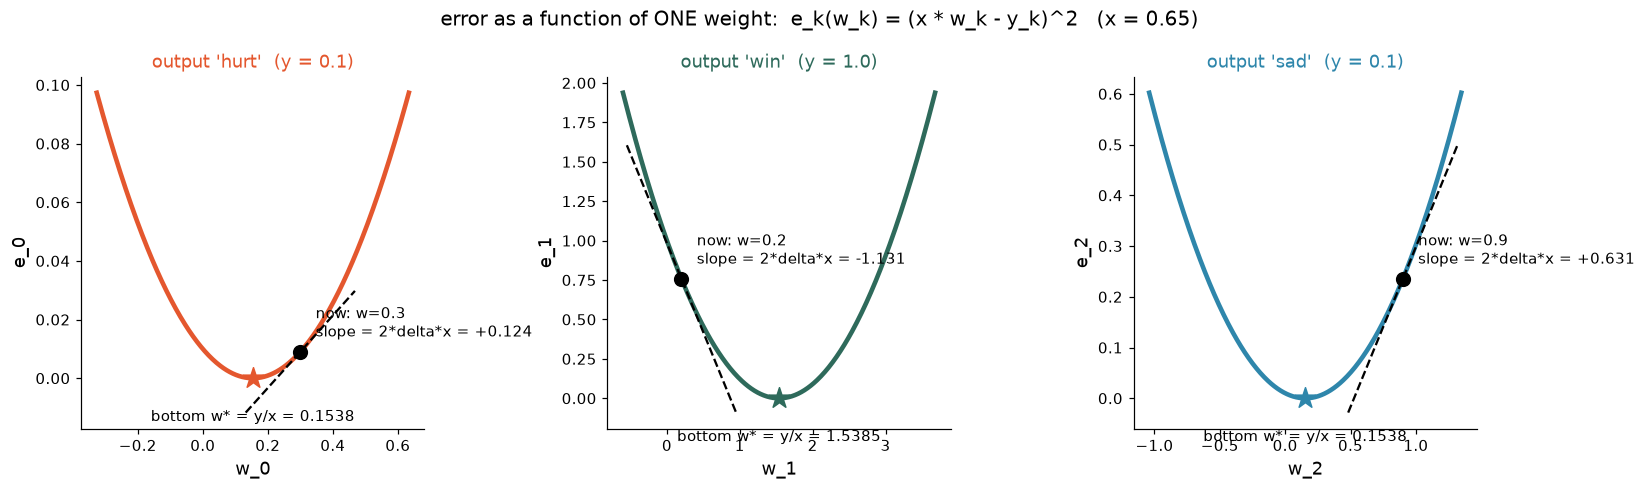

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

x = 0.65
y = [0.1, 1.0, 0.1]
w_init = [0.3, 0.2, 0.9]
alpha = 0.1
NAMES = ["hurt", "win", "sad"]
COLORS = ["#e4572e", "#2e6a5b", "#2e86ab"]


def error(w, k):
    return (x * w - y[k]) ** 2


print("승리 출력: e1(w1) = (0.65*w1 - 1)^2")
print(f"{'w1':>8} {'p1':>8} {'delta1':>9} {'e1':>9}")
for w in [0, 0.2, 0.5, 1.0, 1 / 0.65, 2.0, 3.0]:
    p = x * w
    d = p - y[1]
    print(f"{w:8.4f} {p:8.4f} {d:+9.4f} {d * d:9.6f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=110)
fig.suptitle("error as a function of ONE weight:  e_k(w_k) = (x * w_k - y_k)^2   (x = 0.65)", fontsize=13)
for k, ax in enumerate(axes):
    w_star = y[k] / x
    span = max(abs(w_init[k] - w_star), 0.3) * 1.6
    ws = np.linspace(w_star - span, w_star + span, 400)
    ax.plot(ws, error(ws, k), color=COLORS[k], lw=3)

    w0 = w_init[k]
    e0 = error(w0, k)
    slope = 2 * (x * w0 - y[k]) * x
    tx = np.linspace(w0 - span * 0.35, w0 + span * 0.35, 2)
    ax.plot(tx, e0 + slope * (tx - w0), color="black", ls="--", lw=1.5)
    ax.scatter(w0, e0, color="black", s=80, zorder=5)
    ax.annotate(f"now: w={w0}\nslope = 2*delta*x = {slope:+.3f}", (w0, e0),
                textcoords="offset points", xytext=(10, 10), fontsize=10)
    ax.scatter(w_star, 0, color=COLORS[k], marker="*", s=200, zorder=5)
    ax.annotate(f"bottom w* = y/x = {w_star:.4f}", (w_star, 0), textcoords="offset points",
                xytext=(0, -28), ha="center", fontsize=10)

    ax.set_title(f"output '{NAMES[k]}'  (y = {y[k]})", fontsize=12, color=COLORS[k])
    ax.set_xlabel(f"w_{k}", fontsize=12)
    ax.set_ylabel(f"e_{k}", fontsize=12)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 2. 기울기: "가중치를 조금 움직이면 오차가 얼마나 변하나"

### 2-1. 직선의 기울기

기울기 = (세로 변화량) ÷ (가로 변화량) 입니다.

$p_1 = 0.65\,w_1$ 은 직선입니다. $w_1$을 1 늘리면 $p_1$은 0.65 늘어나므로 기울기는 $0.65 = x$ 입니다.
일반적으로 가중치를 $h$만큼 움직이면 예측은 $x\cdot h$만큼 움직입니다.

> **입력 $x$는 "이 가중치가 예측을 움직이는 힘"** 입니다. 이 사실이 뒤에서 계속 쓰입니다.

### 2-2. 곡선의 기울기

포물선은 위치마다 가파른 정도가 다릅니다. 그래서 "어떤 점에서의 기울기"는 그 점에서 **아주 조금($h$)만 움직여 보고** 구합니다.

$$\text{기울기} \approx \frac{e(w+h) - e(w)}{h}$$

$h$가 작을수록 정확해집니다. 승리 출력, $w_1 = 0.2$ ($e = 0.7569$) 에서 직접 계산해 봅니다.

| $h$ | $w_1+h$ | $p_1$ | $\delta_1$ | $e(w_1+h)$ | $e(w_1+h)-e(w_1)$ | $\div h$ |
|---|---|---|---|---|---|---|
| 0.1 | 0.3 | 0.195 | −0.805 | 0.648025 | −0.108875 | −1.08875 |
| 0.01 | 0.21 | 0.1365 | −0.8635 | 0.74563225 | −0.01126775 | −1.126775 |
| 0.001 | 0.201 | 0.13065 | −0.86935 | 0.7557694225 | −0.0011305775 | −1.1305775 |
| → 0 | | | | | | **−1.131** |

### 2-3. 미분 공식 없이 기울기를 정확히 구하기

가중치를 $h$만큼 움직이면 차례로 이렇게 됩니다.

1. 예측: $p \;\to\; p + xh$ (2-1에서 본 대로)
2. delta: $\delta \;\to\; \delta + xh$ (정답 $y$는 고정이므로 예측이 늘어난 만큼 그대로)
3. 오차: $\delta^2 \;\to\; (\delta + xh)^2$

오차가 변한 양을 구합니다. 전개 공식 $(a+b)^2 = a^2 + 2ab + b^2$ 에서 $a=\delta,\ b=xh$ 로 놓으면

$$(\delta + xh)^2 - \delta^2 = \big(\delta^2 + 2\,\delta\,xh + x^2h^2\big) - \delta^2 = 2\,\delta\,x\,h + x^2h^2$$

양변을 $h$로 나누면

$$\frac{e(w+h)-e(w)}{h} = 2\,\delta\,x + x^2 h$$

$h$를 0에 한없이 가깝게 하면 $x^2h$ 는 0이 되어 사라집니다.

$$\boxed{\;\text{기울기} = 2\,\delta\,x\;}$$

- 검산: $2\times(-0.87)\times0.65 = -1.131$. 위 표에서 $h$가 작아질수록 다가가던 값입니다.
- 위 표의 각 줄도 $-1.131 + 0.4225\,h$ 와 정확히 같습니다 ($x^2 = 0.4225$). 예: $h=0.1$ 이면 $-1.131+0.04225=-1.08875$.

이렇게 $h \to 0$ 으로 보낸 기울기를 수학에서는 **미분(도함수)** 이라 부르고 $\dfrac{de}{dw}$ 로 씁니다.
방금 한 계산이 미분입니다. 미분 공식(연쇄 법칙 등)은 이 계산을 매번 하지 않으려고 정리해 둔 결과일 뿐입니다.

### 2-4. 그래서 책의 `weight_delta = input × delta` 는

$$\text{weight\_delta} = x\cdot\delta = \tfrac{1}{2}\times\text{기울기}$$

책은 앞의 2를 떼었습니다. 다음 단계에서 어차피 α를 곱해 보폭을 정하므로 2는 α에 흡수된 셈입니다
(α=0.1로 `x·δ`를 빼는 것 = 진짜 기울기에 0.05를 곱해 빼는 것). 방향은 똑같습니다.

공식의 두 재료에는 각각 뜻이 있습니다.

- $\delta$: 출력이 **얼마나, 어느 방향으로** 틀렸나 (출력 쪽 사정)
- $x$: 이 가중치가 그 출력을 **얼마나 세게** 움직일 수 있나 (입력 쪽 사정)
  - $x=0$이면 가중치를 어떻게 바꿔도 예측이 안 변하므로 고칠 이유가 없고, 공식도 0이 됩니다.
  - $x$가 음수면 가중치를 올릴 때 예측이 내려가서 방향이 뒤집히는데, 곱셈의 부호가 이를 자동으로 처리합니다.

## 3. 왜 "기울기의 반대 방향"으로 움직이나

갱신식은 이것입니다.

$$w_{\text{new}} = w - \alpha\cdot(x\cdot\delta)$$

| 기울기 부호 | 뜻 | 내리막 방향 | $-\alpha\times$기울기 | 결과 |
|---|---|---|---|---|
| $+$ | $w$를 늘리면 오차↑ | 왼쪽 ($w$↓) | 음수 | $w$ 감소 ✓ |
| $-$ | $w$를 늘리면 오차↓ | 오른쪽 ($w$↑) | 양수 | $w$ 증가 ✓ |
| $0$ | 바닥 | 없음 | 0 | 멈춤 ✓ |

기울기를 **빼기만 하면** 부호가 알아서 내리막을 가리킵니다.
또 바닥에서 멀수록 기울기가 크므로 크게 움직이고, 가까울수록 작게 움직입니다.

**α가 필요한 이유**: 기울기는 "지금 이 점에서"만 맞는 정보입니다. 너무 크게 뛰면 바닥을 지나쳐
반대편 벽의 더 높은 곳에 떨어질 수 있습니다. α는 보폭을 줄이는 장치이고, 얼마부터 위험한지는 5-3절에서 정확한 식으로 구합니다.

## 4. 출력이 3개가 되면: 편미분과 독립성

### 4-1. 전체 오차

출력이 3개이므로 오차도 3개입니다. 신경망 전체가 얼마나 틀렸는지는 합으로 볼 수 있습니다.

$$E(w_0,w_1,w_2) = (xw_0-y_0)^2 + (xw_1-y_1)^2 + (xw_2-y_2)^2 = e_0 + e_1 + e_2$$

이제 오차는 **변수가 3개인 함수**입니다. 그래프로 그리면 축이 4개(가중치 3 + 오차 1)라 그릴 수 없습니다.
5장 앞 절(복수 입력)에서 a, b, c 그래프를 "4차원 도형의 단면"이라고 한 것과 같은 상황입니다.

### 4-2. 편미분: 하나만 움직이고 나머지는 고정

변수가 여럿이면 **하나만 $h$ 움직이고 나머지는 그대로 둔** 기울기를 변수마다 따로 구합니다.
이것을 **편미분**이라 하고 $\dfrac{\partial E}{\partial w_1}$ 처럼 씁니다. ∂ 기호는 "이 변수만 움직였다"는 표시입니다.

$w_1$만 $h$ 움직이면:

- 변하는 예측은 $p_1 = x\,w_1$ 하나뿐입니다. $p_0 = x\,w_0$, $p_2 = x\,w_2$ 에는 $w_1$이 들어 있지 않습니다.
- 그래서 $E$의 세 항 중 둘째 항($e_1$)만 변하고, $e_0$와 $e_2$는 그대로입니다. 변하지 않는 값의 변화량은 0입니다.

$$\frac{\partial E}{\partial w_1} = 0 + 2\,\delta_1\,x + 0 = 2\,\delta_1\,x$$

같은 방법으로

$$\frac{\partial E}{\partial w_0} = 2\,\delta_0\,x,\qquad \frac{\partial E}{\partial w_2} = 2\,\delta_2\,x$$

### 4-3. 결론: 출력 3개짜리 문제 = 출력 1개짜리 문제 3개

각 가중치의 기울기에는 **자기 출력의 delta만** 들어 있습니다. 그래서

- 세 가중치는 서로의 학습에 영향을 주지 않습니다 (**독립**).
- 각자 자기 오차 $e_k$만 줄이면 합 $E$도 줄어듭니다.
- 4장의 단일 가중치 경사하강법을 세 번 하는 것과 **완전히 같습니다**.

책이 "이번 절은 조금 뻔합니다"라고 한 이유가 이것입니다. 새로 배울 수학이 없다는 것이 이 절의 메시지입니다.
아래 셀은 가중치를 하나씩 $h = 0.001$ 만큼 움직였을 때 세 오차가 각각 얼마나 변하는지 숫자로 보여 줍니다.
대각선(자기 출력)만 0이 아니고 나머지는 정확히 0입니다.

### 4-4. 벡터로 한 번에 쓰기

세 값을 묶어 벡터(숫자 목록)로 쓰면

$$\mathbf{w} = [w_0,\ w_1,\ w_2],\qquad \boldsymbol\delta = [\delta_0,\ \delta_1,\ \delta_2]$$

$$\text{weight\_deltas} = x\,\boldsymbol\delta = [x\delta_0,\ x\delta_1,\ x\delta_2],\qquad \mathbf{w}_{\text{new}} = \mathbf{w} - \alpha\,x\,\boldsymbol\delta$$

숫자 하나($x$)를 벡터의 칸마다 곱하는 것이 책의 `scalar_ele_mul` 입니다. 곱하는 상대는 **delta** 입니다.

> **책 오타 주의**: 131쪽 코드 마지막 줄 `scalar_ele_mul(input, weights)` 는 `weights`가 아니라 `delta`여야 합니다.
> 그림의 0.062, −0.57, 0.315 는 $0.65\times\delta_k$ 값입니다.

In [2]:
h = 0.001
w = list(w_init)
base = [error(w[k], k) for k in range(3)]

print("가중치 하나만 h=0.001 움직였을 때, 각 오차의 변화량 / h")
print(f"{'':14}{'e0 (hurt)':>12}{'e1 (win)':>12}{'e2 (sad)':>12}   {'2*delta_j*x':>12}")
for j in range(3):
    moved = list(w)
    moved[j] += h
    change = [(error(moved[k], k) - base[k]) / h for k in range(3)]
    exact = 2 * (x * w[j] - y[j]) * x
    print(f"w{j} 만 +h    " + "".join(f"{c:+12.4f}" for c in change) + f"   {exact:+12.4f}")

가중치 하나만 h=0.001 움직였을 때, 각 오차의 변화량 / h
                 e0 (hurt)    e1 (win)    e2 (sad)    2*delta_j*x
w0 만 +h         +0.1239     +0.0000     +0.0000        +0.1235
w1 만 +h         +0.0000     -1.1306     +0.0000        -1.1310
w2 만 +h         +0.0000     +0.0000     +0.6309        +0.6305


## 5. 종이로 따라하는 계산

### 5-1. 1회차 (책 131~132쪽)

| 단계 | 식 | 부상 ($k=0$) | 승리 ($k=1$) | 슬픔 ($k=2$) |
|---|---|---|---|---|
| ① 예측 | $p_k = x\,w_k$ | 0.65×0.3 = 0.195 | 0.65×0.2 = 0.13 | 0.65×0.9 = 0.585 |
| ② delta | $\delta_k = p_k - y_k$ | 0.195−0.1 = **+0.095** | 0.13−1 = **−0.87** | 0.585−0.1 = **+0.485** |
| ③ 오차 | $e_k=\delta_k^{\,2}$ | 0.009025 | 0.7569 | 0.235225 |
| ④ weight_delta | $x\,\delta_k$ | 0.65×0.095 = 0.06175 | 0.65×(−0.87) = −0.5655 | 0.65×0.485 = 0.31525 |
| ⑤ 보폭 | $\alpha\,x\,\delta_k$ | 0.006175 | −0.05655 | 0.031525 |
| ⑥ 새 가중치 | $w_k - ⑤$ | 0.3−0.006175 = **0.293825** | 0.2+0.05655 = **0.25655** | 0.9−0.031525 = **0.868475** |

132쪽 ④번 그림의 0.29, 0.26, 0.87 은 ⑥행을 반올림한 값입니다.
②의 부호와 ⑥의 방향을 비교해 보세요. 너무 높은 부상·슬픔은 가중치가 줄고, 너무 낮은 승리는 늘었습니다.

### 5-2. 2회차 연습

⑥의 값을 새 $w_k$로 놓고 ①부터 다시 합니다. 승리 출력의 답입니다.

$$p_1 = 0.65\times0.25655 = 0.1667575,\quad \delta_1 = -0.8332425,\quad e_1 \approx 0.694293$$
$$x\,\delta_1 = -0.54160763,\quad w_1 = 0.25655 + 0.054160763 = 0.310710763$$

나머지 두 출력과 3회차 이후는 아래 셀이 출력하는 표로 맞춰 보세요.

### 5-3. 반복하면 어떻게 되나: 한 줄 식으로 정리

갱신식에 $\delta = x\,w - y$ 를 대입합니다.

$$w_{t+1} = w_t - \alpha\,x\,(x\,w_t - y)$$

바닥 $w^* = y/x$ 를 쓰면 $x\,w_t - y = x\,(w_t - w^*)$ 이므로 ($x$로 묶어 냄)

$$w_{t+1} = w_t - \alpha\,x^2\,(w_t - w^*)$$

양변에서 $w^*$를 빼면

$$\boxed{\;w_{t+1} - w^* = (1-\alpha x^2)\,(w_t - w^*)\;}$$

**바닥까지 남은 거리가 한 번 갱신할 때마다 $(1-\alpha x^2)$ 배가 된다**는 뜻입니다. 이 절의 값으로는

$$1-\alpha x^2 = 1 - 0.1\times0.4225 = 0.95775$$

즉 매번 남은 거리의 4.225%만큼 다가갑니다. $t$번 반복한 뒤에는

$$w_t = w^* + (0.95775)^t\,(w_0 - w^*)$$

오차는 $e = \delta^2 = x^2\,(w-w^*)^2$ 이므로 매번 $(0.95775)^2 \approx 0.9173$ 배가 됩니다.

검산 (승리): 처음 거리 $0.2 - 1.53846 = -1.33846$, 1회 후 $0.25655 - 1.53846 = -1.28191$, 비율 $= 0.95775$ ✓

이 식에서 읽히는 것:

- **세 출력 모두 같은 비율(0.95775)로 다가갑니다.** 비율에는 $x$와 $\alpha$만 들어 있고, 셋이 같은 입력을 쓰기 때문입니다.
  처음 거리가 달라서 실제로 움직이는 양은 다릅니다 (승리가 바닥에서 가장 멀어 가장 크게 움직임).
- 비율이 1에 가까울수록 느립니다. 0.95775면 남은 거리가 절반이 되는 데 약 16회 걸립니다 ($0.95775^{16}\approx0.50$).
- **α가 너무 크면 발산합니다.** 거리가 줄려면 $|1-\alpha x^2| < 1$, 즉 $0<\alpha<2/x^2 \approx 4.73$ 이어야 합니다.

| $\alpha x^2$ 범위 | 이 예제의 α | 움직임 |
|---|---|---|
| 0 ~ 1 | α < 2.37 | 한쪽에서 미끄러지듯 다가감 |
| = 1 | α ≈ 2.37 | 한 번에 바닥 |
| 1 ~ 2 | 2.37 < α < 4.73 | 바닥을 넘었다 돌아오며 진동, 그래도 수렴 |
| > 2 | α > 4.73 | 넘을 때마다 더 멀어짐 → **발산** |

아래 첫 셀은 반복 테이블과 그래프를, 둘째 셀은 α에 따른 네 가지 움직임을 그립니다.

[hurt]  x = 0.65,  y = 0.1,  alpha = 0.1,  w* = y/x = 0.15385
  t        w_t      p=x*w      delta      error    x*delta      w_t+1   w_t - w*    ratio
  0   0.300000   0.195000  +0.095000   0.009025  +0.061750   0.293825  +0.146154 
  1   0.293825   0.190986  +0.090986   0.008278  +0.059141   0.287911  +0.139979  0.95775
  2   0.287911   0.187142  +0.087142   0.007594  +0.056642   0.282247  +0.134065  0.95775
  3   0.282247   0.183460  +0.083460   0.006966  +0.054249   0.276822  +0.128401  0.95775
  4   0.276822   0.179934  +0.079934   0.006389  +0.051957   0.271626  +0.122976  0.95775
  5   0.271626   0.176557  +0.076557   0.005861  +0.049762   0.266650  +0.117780  0.95775
  6   0.266650   0.173322  +0.073322   0.005376  +0.047660   0.261884  +0.112804  0.95775
  7   0.261884   0.170225  +0.070225   0.004931  +0.045646   0.257319  +0.108038  0.95775
  8   0.257319   0.167258  +0.067258   0.004524  +0.043717   0.252948  +0.103473  0.95775
  9   0.252948   0.164416  +0.064416   0.00414

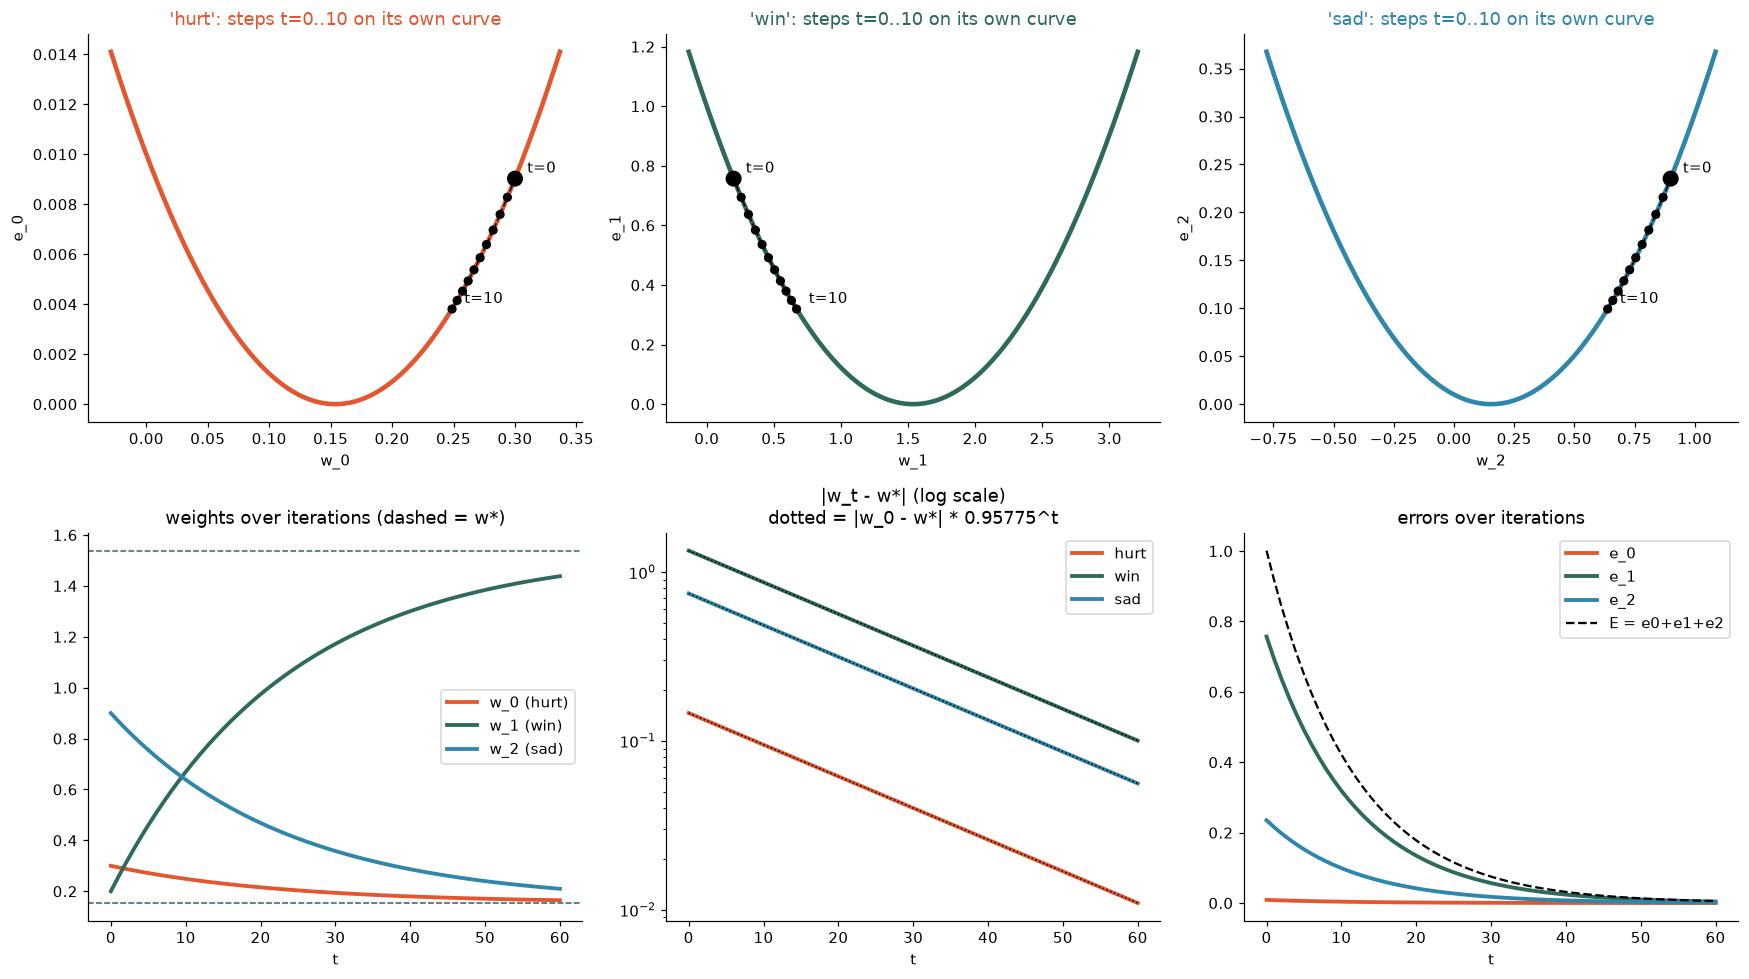

In [3]:
T = 60
hist = []  # hist[t][k] = (w, p, delta, error, x*delta, w_new)
w = list(w_init)
for t in range(T + 1):
    row = []
    for k in range(3):
        p = x * w[k]
        d = p - y[k]
        wd = x * d
        nw = w[k] - alpha * wd
        row.append((w[k], p, d, d * d, wd, nw))
        w[k] = nw
    hist.append(row)

for k in range(3):
    w_star = y[k] / x
    print(f"[{NAMES[k]}]  x = {x},  y = {y[k]},  alpha = {alpha},  w* = y/x = {w_star:.5f}")
    print(f"{'t':>3} {'w_t':>10} {'p=x*w':>10} {'delta':>10} {'error':>10} {'x*delta':>10} "
          f"{'w_t+1':>10} {'w_t - w*':>10} {'ratio':>8}")
    for t in range(11):
        wv, p, d, e, wd, nw = hist[t][k]
        ratio = "" if t == 0 else f"{(wv - w_star) / (hist[t - 1][k][0] - w_star):8.5f}"
        print(f"{t:3d} {wv:10.6f} {p:10.6f} {d:+10.6f} {e:10.6f} {wd:+10.6f} {nw:10.6f} "
              f"{wv - w_star:+10.6f} {ratio}")
    print()

ts = np.arange(T + 1)
fig, axes = plt.subplots(2, 3, figsize=(16, 9), dpi=110)

for k in range(3):
    ax = axes[0, k]
    w_star = y[k] / x
    span = abs(w_init[k] - w_star) * 1.25
    ws = np.linspace(w_star - span, w_star + span, 400)
    ax.plot(ws, error(ws, k), color=COLORS[k], lw=3)
    pw = [hist[t][k][0] for t in range(11)]
    pe = [hist[t][k][3] for t in range(11)]
    ax.plot(pw, pe, color="black", lw=1, ls="--")
    ax.scatter(pw, pe, color="black", s=[90] + [25] * 10, zorder=5)
    ax.annotate("t=0", (pw[0], pe[0]), textcoords="offset points", xytext=(8, 4))
    ax.annotate("t=10", (pw[10], pe[10]), textcoords="offset points", xytext=(8, 4))
    ax.set_title(f"'{NAMES[k]}': steps t=0..10 on its own curve", color=COLORS[k], fontsize=12)
    ax.set_xlabel(f"w_{k}")
    ax.set_ylabel(f"e_{k}")
    ax.spines[["top", "right"]].set_visible(False)

ax = axes[1, 0]
for k in range(3):
    ax.plot(ts, [hist[t][k][0] for t in ts], color=COLORS[k], lw=2.5, label=f"w_{k} ({NAMES[k]})")
    ax.axhline(y[k] / x, color=COLORS[k], ls="--", lw=1)
ax.set_title("weights over iterations (dashed = w*)", fontsize=12)
ax.set_xlabel("t")
ax.legend()

ax = axes[1, 1]
for k in range(3):
    w_star = y[k] / x
    ax.plot(ts, [abs(hist[t][k][0] - w_star) for t in ts], color=COLORS[k], lw=2.5, label=NAMES[k])
    ax.plot(ts, abs(w_init[k] - w_star) * (1 - alpha * x ** 2) ** ts, color="black", ls=":", lw=1)
ax.set_yscale("log")
ax.set_title("|w_t - w*| (log scale)\ndotted = |w_0 - w*| * 0.95775^t", fontsize=12)
ax.set_xlabel("t")
ax.legend()

ax = axes[1, 2]
for k in range(3):
    ax.plot(ts, [hist[t][k][3] for t in ts], color=COLORS[k], lw=2.5, label=f"e_{k}")
ax.plot(ts, [sum(hist[t][k][3] for k in range(3)) for t in ts], color="black", lw=1.5, ls="--",
        label="E = e0+e1+e2")
ax.set_title("errors over iterations", fontsize=12)
ax.set_xlabel("t")
ax.legend()

for ax in axes[1]:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

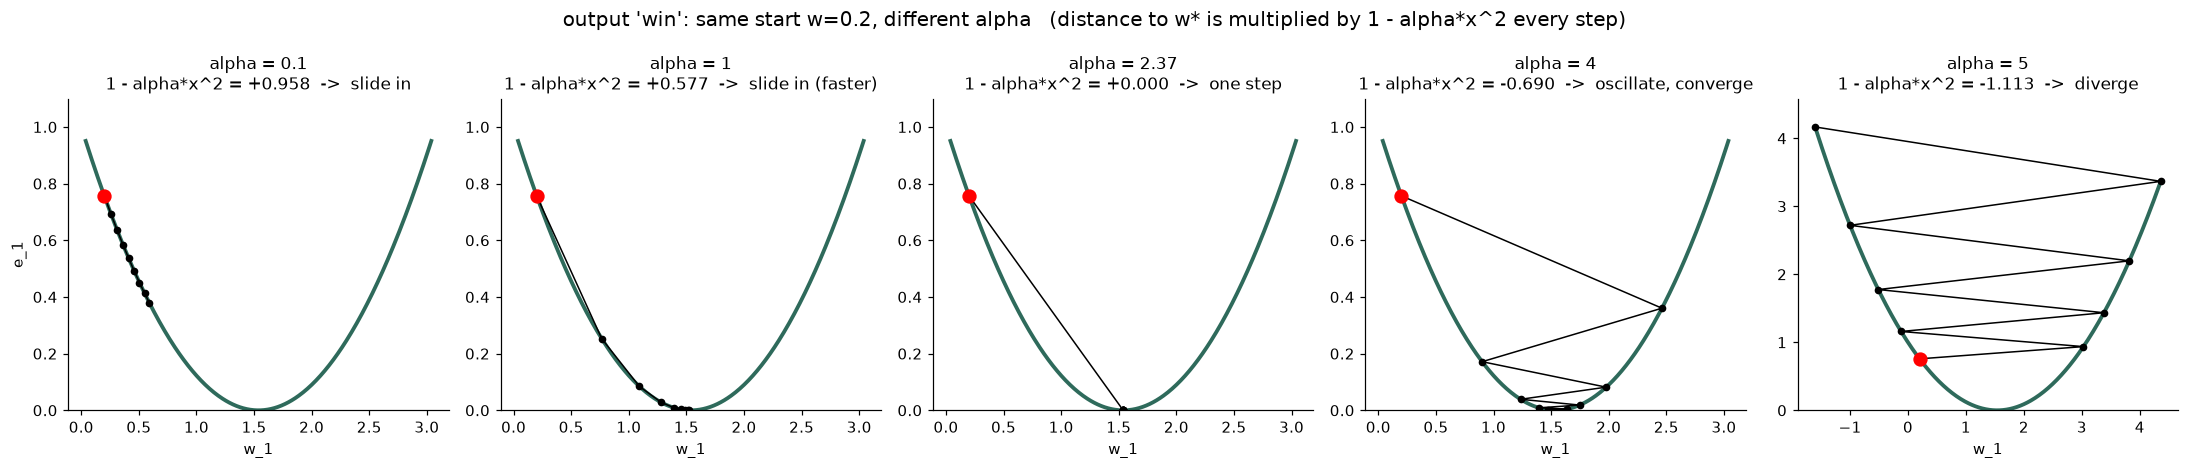

In [4]:
k = 1
w_star = y[k] / x
cases = [0.1, 1.0, 1 / x ** 2, 4.0, 5.0]
labels = ["slide in", "slide in (faster)", "one step", "oscillate, converge", "diverge"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4.3), dpi=110)
fig.suptitle("output 'win': same start w=0.2, different alpha   "
             "(distance to w* is multiplied by 1 - alpha*x^2 every step)", fontsize=13)
for ax, a, lab in zip(axes, cases, labels):
    factor = 1 - a * x ** 2
    w = w_init[k]
    path = [w]
    for _ in range(8):
        w = w - a * x * (x * w - y[k])
        path.append(w)
    path = np.array(path)

    lo, hi = min(path.min(), w_star - 1.5), max(path.max(), w_star + 1.5)
    ws = np.linspace(lo, hi, 400)
    ax.plot(ws, error(ws, k), color=COLORS[k], lw=2.5)
    ax.plot(path, error(path, k), color="black", lw=1, marker="o", ms=4)
    ax.scatter(path[0], error(path[0], k), color="red", s=70, zorder=5)
    ax.set_ylim(0, max(error(path, k).max(), 1.0) * 1.1)
    ax.set_title(f"alpha = {a:.3g}\n1 - alpha*x^2 = {factor:+.3f}  ->  {lab}", fontsize=11)
    ax.set_xlabel("w_1")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("e_1")
plt.tight_layout()
plt.show()

## 6. 일반화: 복수 입력·복수 출력, 그리고 "한 가지 원리"

### 6-1. 번호가 두 개인 가중치

입력 $j$와 출력 $i$를 잇는 가중치를 $w_{ij}$ 라 합니다. 책 코드 `weights[i][j]` 와 같습니다 (행 = 출력, 열 = 입력).

$$p_i = \sum_{j} w_{ij}\,x_j = w_{i0}\,x_0 + w_{i1}\,x_1 + w_{i2}\,x_2$$

$\sum_j$ 는 "$j$를 0, 1, 2로 바꿔 가며 모두 더하라"는 기호이고, 책의 `w_sum` 입니다.

### 6-2. 같은 방법으로 기울기 구하기

$w_{ij}$ 하나만 $h$ 움직이면:

- 그 가중치가 들어 있는 예측은 $p_i$ 하나뿐이고, $x_j\,h$ 만큼 변합니다 (2-1과 같은 이유).
- 그래서 $\delta_i$ 만 $x_j h$ 변하고, 다른 출력의 오차는 그대로입니다.

2-3의 대수를 그대로 반복하면

$$\frac{\partial E}{\partial w_{ij}} = 2\,\delta_i\,x_j \qquad\Rightarrow\qquad \text{weight\_delta}_{ij} = \delta_i\,x_j$$

### 6-3. 지금까지의 모든 경우가 이 한 줄

| 경우 | 가중치 | weight_delta | 특징 |
|---|---|---|---|
| 4장 (입력 1, 출력 1) | $w$ | $\delta\,x$ | |
| 복수 입력 (입력 3, 출력 1) | $w_j$ | $\delta\,x_j$ | 같은 δ, 다른 x |
| 복수 출력 (입력 1, 출력 3) | $w_i$ | $\delta_i\,x$ | 다른 δ, 같은 x |
| 복수 입력·복수 출력 | $w_{ij}$ | $\delta_i\,x_j$ | 모든 짝 |

마지막 경우의 모든 $(i, j)$ 짝을 표로 늘어놓은 것이 **외적(outer product)** 입니다.
행에 δ, 열에 x를 적고 칸마다 곱하면 됩니다. 구구단 표를 만드는 것과 같습니다.

복수 출력과 복수 입력의 차이도 하나 짚어 둡니다. 복수 출력에서는 가중치끼리 **독립**이었지만 복수 입력에서는 아닙니다.
한 출력을 여러 가중치가 함께 만들기 때문에, 하나를 바꾸면 그 출력의 δ가 변하고 나머지 가중치들의 기울기도 변합니다.
그래도 **매 순간 쓰는 공식은 같습니다.** 이 얽힘 때문에 오차 곡면이 여러 차원으로 휘어지고, 5장 앞부분에서 3D·4D 그림이 필요했습니다.

### 6-4. 책 132~133쪽 숫자로 외적 계산

$x = [8.5,\ 0.65,\ 1.2]$ (발가락 수, 승률, 관중 수), 정답 $y = [0.1,\ 1,\ 0.1]$, 아래 셀이 예측, δ, 외적 표, 갱신된 가중치를 모두 출력합니다.

> **책 주의점**
> - 133쪽 오차 칸의 0.96 은 $(-0.02)^2 = 0.0004$ 의 오기로 보입니다 (0.207 = 0.455², 0.748 = 0.865² 는 맞음).
> - 책의 `outer_prod(input, delta)` 는 `[입력][출력]` 순서로 표를 만드는데 `weights` 는 `[출력][입력]` 순서여서 행과 열이 뒤바뀝니다.
>   수학적으로 맞는 것은 $\delta_i\,x_j$ (행 = 출력) 이고, 아래 셀은 그렇게 계산합니다.

### 6-5. "확률적" 경사하강법

- **경사하강법**: 기울기의 반대 방향으로 조금씩 내려가는 것.
- **확률적(stochastic)**: 데이터 전체(4경기)의 오차를 모두 모아 기울기를 구하지 않고, **예제 하나(한 경기)만 보고 바로 갱신**한 뒤 다음 예제로 넘어가는 방식.
  이번 절이 `wlrec[0]` 하나만 쓴 것이 바로 그 한 걸음입니다. 예제 하나의 기울기는 전체 기울기의 추정치라 조금씩 흔들리지만(그래서 '확률적'), 계산이 싸고 대개 잘 수렴합니다.

마지막 셀은 4경기를 번갈아 보며 복수 출력 신경망을 학습시킵니다. 입력 하나에 가중치 하나라서 4경기를 모두 정확히 맞출 수는 없고,
가중치는 **4경기 오차 합이 가장 작은 값** $w = \dfrac{\sum x\,y}{\sum x^2}$ (점선) 근처에서 경기마다 조금씩 흔들리며 머뭅니다.

### 6-6. 다시, 저자의 의도

- 4장: 가중치 1개 → 기울기 = 입력 × delta.
- 5장: 가중치가 몇 개든 → **각 가중치마다 따로** 입력 × delta. 짝만 잘 맞추면 된다.
- 6장 이후 층이 깊어지면 중간(은닉) 노드의 δ를 구하는 방법(역전파)이 더해집니다. 그래도 가중치 갱신은 언제나
  **"가중치 앞쪽 값 × 가중치 뒤쪽 δ"** 입니다.

"다양한 아키텍처가 한 가지 원리를 일관되게 사용한다"는 문장이 가리키는 것이 이 표 한 장(6-3)입니다.

① 예측  p_i = w_i0*x0 + w_i1*x1 + w_i2*x2
   p0 (hurt) = 0.1*8.5 + 0.1*0.65 + -0.3*1.2 = 0.5550
   p1 (win ) = 0.1*8.5 + 0.2*0.65 + 0.0*1.2 = 0.9800
   p2 (sad ) = 0.0*8.5 + 1.3*0.65 + 0.1*1.2 = 0.9650

② delta_i = p_i - y_i,  error_i = delta_i^2
   delta0 = 0.5550 - 0.1 = +0.4550,   error0 = 0.2070
   delta1 = 0.9800 - 1.0 = -0.0200,   error1 = 0.0004
   delta2 = 0.9650 - 0.1 = +0.8650,   error2 = 0.7482

③ 외적  weight_delta[i][j] = delta_i * x_j   (행 = 출력 i, 열 = 입력 j)
                          toes 8.5      wlrec 0.65       nfans 1.2
   hurt d=+0.455           +3.8675         +0.2958         +0.5460
   win  d=-0.020           -0.1700         -0.0130         -0.0240
   sad  d=+0.865           +7.3525         +0.5623         +1.0380

④ 새 가중치  w_ij - 0.01 * weight_delta[i][j]
   hurt    0.10 -> +0.0613     0.10 -> +0.0970    -0.30 -> -0.3055   
   win     0.10 -> +0.1017     0.20 -> +0.2001     0.00 -> +0.0002   
   sad     0.00 -> -0.0735     1.30 -> +1.2944     0.10 -> +0.0896   


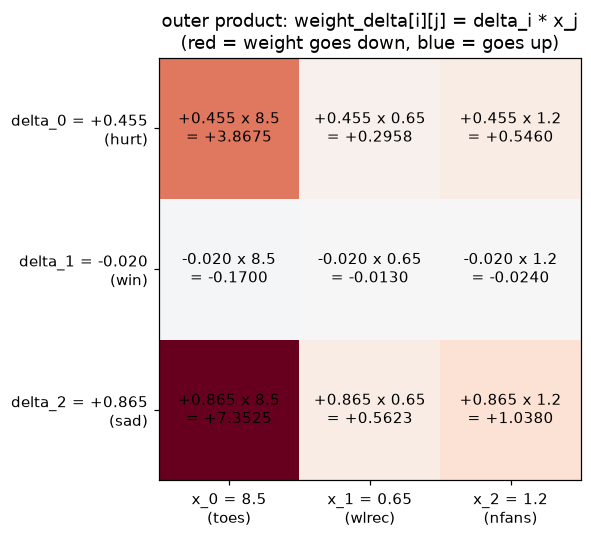

In [5]:
xs = np.array([8.5, 0.65, 1.2])
ys = np.array([0.1, 1.0, 0.1])
W = np.array([[0.1, 0.1, -0.3],
              [0.1, 0.2, 0.0],
              [0.0, 1.3, 0.1]])
alpha_m = 0.01
IN = ["toes", "wlrec", "nfans"]

print("① 예측  p_i = w_i0*x0 + w_i1*x1 + w_i2*x2")
p = np.zeros(3)
for i in range(3):
    terms = " + ".join(f"{W[i, j]}*{xs[j]}" for j in range(3))
    p[i] = sum(W[i, j] * xs[j] for j in range(3))
    print(f"   p{i} ({NAMES[i]:4}) = {terms} = {p[i]:.4f}")

d = p - ys
print("\n② delta_i = p_i - y_i,  error_i = delta_i^2")
for i in range(3):
    print(f"   delta{i} = {p[i]:.4f} - {ys[i]} = {d[i]:+.4f},   error{i} = {d[i] ** 2:.4f}")

WD = np.array([[d[i] * xs[j] for j in range(3)] for i in range(3)])
print("\n③ 외적  weight_delta[i][j] = delta_i * x_j   (행 = 출력 i, 열 = 입력 j)")
print(f"{'':18}" + "".join(f"{IN[j] + ' ' + str(xs[j]):>16}" for j in range(3)))
for i in range(3):
    print(f"   {NAMES[i]:4} d={d[i]:+.3f}  " + "".join(f"{WD[i, j]:+16.4f}" for j in range(3)))

W_new = W - alpha_m * WD
print(f"\n④ 새 가중치  w_ij - {alpha_m} * weight_delta[i][j]")
for i in range(3):
    print(f"   {NAMES[i]:4}  " + "".join(f"{W[i, j]:6.2f} -> {W_new[i, j]:+.4f}   " for j in range(3)))

fig, ax = plt.subplots(figsize=(7, 5), dpi=110)
lim = np.abs(WD).max()
ax.imshow(WD, cmap="RdBu_r", vmin=-lim, vmax=lim)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{d[i]:+.3f} x {xs[j]}\n= {WD[i, j]:+.4f}", ha="center", va="center", fontsize=10)
ax.set_xticks(range(3), [f"x_{j} = {xs[j]}\n({IN[j]})" for j in range(3)])
ax.set_yticks(range(3), [f"delta_{i} = {d[i]:+.3f}\n({NAMES[i]})" for i in range(3)])
ax.set_title("outer product: weight_delta[i][j] = delta_i * x_j\n(red = weight goes down, blue = goes up)")
plt.tight_layout()
plt.show()

첫 번째 바퀴 (경기 하나 볼 때마다 바로 갱신)
game     x        y (h,w,s)              delta (h,w,s)              new w (h,w,s)
   0  0.65      0.1, 1, 0.1  +0.0950  -0.8700  +0.4850    0.2938   0.2566   0.8685
   1  1.00          0, 1, 0  +0.2938  -0.7434  +0.8685    0.2644   0.3309   0.7816
   2  1.00        0, 0, 0.1  +0.2644  +0.3309  +0.6816    0.2380   0.2978   0.7135
   3  0.90      0.1, 1, 0.2  +0.1142  -0.7320  +0.4421    0.2277   0.3637   0.6737


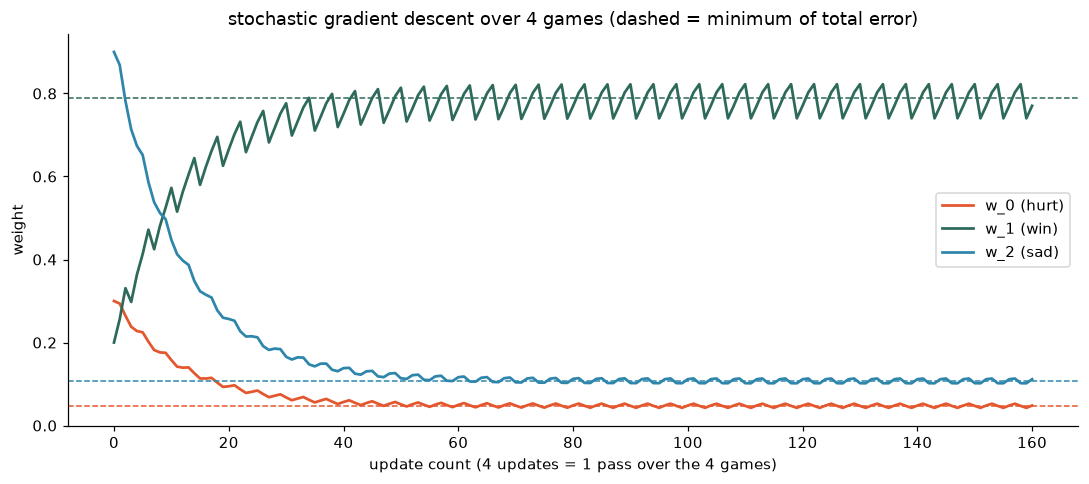

In [6]:
wlrec = [0.65, 1.0, 1.0, 0.9]
hurt = [0.1, 0.0, 0.0, 0.1]
win = [1, 1, 0, 1]
sad = [0.1, 0.0, 0.1, 0.2]
targets = [hurt, win, sad]

w = list(w_init)
print("첫 번째 바퀴 (경기 하나 볼 때마다 바로 갱신)")
print(f"{'game':>4} {'x':>5} {'y (h,w,s)':>16} {'delta (h,w,s)':>26} {'new w (h,w,s)':>26}")
trace = [list(w)]
for epoch in range(40):
    for g in range(4):
        xg = wlrec[g]
        ds = [xg * w[k] - targets[k][g] for k in range(3)]
        w = [w[k] - alpha * xg * ds[k] for k in range(3)]
        trace.append(list(w))
        if epoch == 0:
            ys_g = ", ".join(f"{targets[k][g]:g}" for k in range(3))
            print(f"{g:4d} {xg:5.2f} {ys_g:>16} " + " ".join(f"{v:+8.4f}" for v in ds) + "  "
                  + " ".join(f"{v:8.4f}" for v in w))
trace = np.array(trace)

sxx = sum(v * v for v in wlrec)
fig, ax = plt.subplots(figsize=(10, 4.5), dpi=110)
for k in range(3):
    best = sum(wlrec[g] * targets[k][g] for g in range(4)) / sxx
    ax.plot(trace[:, k], color=COLORS[k], lw=1.8, label=f"w_{k} ({NAMES[k]})")
    ax.axhline(best, color=COLORS[k], ls="--", lw=1)
ax.set_xlabel("update count (4 updates = 1 pass over the 4 games)")
ax.set_ylabel("weight")
ax.set_title("stochastic gradient descent over 4 games (dashed = minimum of total error)")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()